# Рисунки к статье «Господство, полномочия, правление: лексика власти у Фомы Аквинского»

Ноутбук лежит в `notebooks/` рядом с `01_main_analysis.ipynb` (можно запускать и из корня репозитория) и самостоятельно воспроизводит основную сеть, сеть ближайших соседей и локальные сети по векторам модели LiLa *Opera Maiora* (fastText skip-gram, 100 измерений) и строит рисунки для основного текста и Приложения. Расчёты повторяют `01_main_analysis.ipynb`: те же целевые леммы, 15 ближайших соседей, порог по условию связности, 50 запусков Лейдена (seed 0–49), медоидное разбиение, сеть восьми ближайших соседей, локальные сети по схеме 6–4.

**Рисунки основного текста**

| № | Файл | Содержание |
|---|---|---|
| 1 | `fig1_networks` | а) пороговая сеть; б) сеть восьми ближайших соседей; одна раскладка |
| 2 | `fig2_similarity_matrix` | квадратная матрица косинусного сходства целевых лемм |
| 3 | `fig3_local_dominium` | локальная сеть *dominium* |
| 4 | `fig4_local_potestas` | локальная сеть *potestas* |
| 5 | `fig5_community_regimen` | сообщество области правления целиком |
| 6 | `fig6_local_principatus` | локальная сеть *principatus* |

Рисунки сохраняются в `figures/article/`. **Приложение:** графы всех семи сообществ (`figures/article/appendix/communities/`) и локальные сети всех одиннадцати целевых лемм (`figures/article/appendix/local_networks/`) в тех же цветах.

**Цвета.** Три контекстные области окрашены одинаково на всех рисунках: господство – синий, должностные полномочия – оранжевый, правление – бирюзовый. Эти три оттенка различимы и при нарушениях цветового зрения. Прочие сообщества – серые, они узнаются по подписанной целевой лемме. В локальных сетях белым показаны леммы, не вошедшие в словарь основной сети. Заголовков внутри изображений нет: они даются в подписях к рисункам. Каждый рисунок сохраняется в PNG (300 dpi) и PDF.

## 1. Среда

In [4]:
import importlib.util, subprocess, sys

REQUIRED = {"gensim": "gensim", "igraph": "igraph", "leidenalg": "leidenalg",
            "seaborn": "seaborn", "adjustText": "adjustText", "networkx": "networkx"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Пакеты на месте" if not missing else f"Установлены: {', '.join(missing)}")

Пакеты на месте


## 2. Параметры

In [5]:
import os, urllib.request
from itertools import combinations

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import seaborn as sns
from adjustText import adjust_text
import igraph as ig
import leidenalg
from gensim.models import KeyedVectors

# --- Модель -----------------------------------------------------------------------
MODEL_URL = "https://embeddings.lila-erc.eu/samples/download/OperaMaiora/opera-maiora-lemmas_skip_100.vec"
# Как в 01_main_analysis.ipynb: при запуске из notebooks/ пути отсчитываются от корня репозитория.
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
MODEL_DIR = os.path.join(ROOT, "models")
MODEL_FILE = os.environ.get("AQUINAS_VEC", os.path.join(MODEL_DIR, "opera-maiora-lemmas_skip_100.vec"))

# --- Целевые леммы (орфография словаря модели) --------------------------------------
TARGET_TERMS = ["dominium", "potestas", "praelatio", "iurisdictio", "auctoritas",
                "imperium", "principatus", "regimen", "gubernatio", "regnum", "dominatio"]

# --- Параметры сети (как в 01_main_analysis.ipynb) ------------------------------------
TOP_N = 15
KNN_K = 8
N_LEIDEN_RUNS = 50
SEED = 42
THRESHOLD_GRID = np.round(np.arange(0.30, 0.801, 0.01), 2)
LOCAL_FIRST, LOCAL_SECOND = 6, 4

# Значения из статьи – для сверки воспроизведения (раздел 4)
EXPECTED = {"Лемм в основной сети": 125, "Порог θ": 0.59, "Рёбер в основной сети": 724,
            "Сообществ медоида": 7, "Рёбер в сети ближайших соседей": 677}

# --- Оформление -----------------------------------------------------------------------
OUT_DIR = os.path.join(ROOT, "figures", "article")
FORMATS = ("png", "pdf")
FIG_DPI = 300
AREAS = [("dominium", "господство", "#2a78d6"),
         ("potestas", "должностные полномочия", "#eb6834"),
         ("regimen", "правление", "#1baf7a")]
OTHER_COLOR = "#cfcec8"       # прочие сообщества основной сети
OUTSIDE_COLOR = "#ffffff"     # леммы вне словаря основной сети (локальные сети)
EDGE_COLOR = "#555555"
LABEL_COLOR = "#171717"
MATRIX_COLOR = "#1f5fa8"      # одноцветная шкала матрицы сходства
LOCAL_FONT = {0: 24, 1: 17, 2: 14}

for folder in (MODEL_DIR, OUT_DIR, os.path.join(OUT_DIR, "appendix", "communities"),
               os.path.join(OUT_DIR, "appendix", "local_networks")):
    os.makedirs(folder, exist_ok=True)

sns.set_style("white")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12, "pdf.fonttype": 42,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})
np.random.seed(SEED)

## 3. Векторы модели

Текстовый файл `.vec` ищется в папке `models/` в корне репозитория и, если его там нет, загружается туда один раз. Для лемм словаря его векторы должны совпадать с векторами двоичной модели `.bin`, которую использует основной ноутбук; это проверяет сверка со статьёй в разделе 4. Другой путь к файлу можно задать переменной окружения `AQUINAS_VEC`.

In [6]:
if not os.path.exists(MODEL_FILE):
    print(f"Загружается {os.path.basename(MODEL_FILE)}…")
    urllib.request.urlretrieve(MODEL_URL, MODEL_FILE)
wv = KeyedVectors.load_word2vec_format(MODEL_FILE, binary=False, unicode_errors="ignore")
absent = [t for t in TARGET_TERMS if t not in wv.key_to_index]
assert not absent, f"Нет в словаре модели: {absent}"
print(f"Словарь модели: {len(wv)} лемм, размерность {wv.vector_size}")

Словарь модели: 6724 лемм, размерность 100


## 4. Расчёт сетей

Функции перенесены из `01_main_analysis.ipynb` без изменений.

In [7]:
def network_lemmas(top_n):
    lemmas = set(TARGET_TERMS)
    for term in TARGET_TERMS:
        lemmas.update(w for w, _ in wv.most_similar(term, topn=top_n))
    return sorted(lemmas)


def similarity_matrix(lemmas):
    v = np.array([wv[w] for w in lemmas], dtype=np.float64)
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    return v @ v.T


def build_network(lemmas, similarity, threshold):
    rows, cols = np.triu_indices(len(lemmas), k=1)
    weights = similarity[rows, cols]
    keep = weights >= threshold
    graph = nx.Graph()
    graph.add_nodes_from(lemmas)
    for i, j, w in zip(rows[keep], cols[keep], weights[keep]):
        graph.add_edge(lemmas[i], lemmas[j], weight=float(w))
    return graph


def build_knn_network(lemmas, similarity, k):
    n = len(lemmas)
    s = np.asarray(similarity, dtype=float).copy()
    np.fill_diagonal(s, -np.inf)
    ids = np.arange(n)
    chosen = np.zeros((n, n), dtype=bool)
    for i in range(n):
        chosen[i, np.lexsort((ids, -s[i]))[:k]] = True
    keep = chosen | chosen.T
    graph = nx.Graph()
    graph.add_nodes_from(lemmas)
    for i, j in zip(*np.where(np.triu(keep, k=1))):
        graph.add_edge(lemmas[i], lemmas[j], weight=float(similarity[i, j]))
    return graph


def connectivity_threshold(lemmas, similarity):
    connected = [t for t in THRESHOLD_GRID
                 if nx.is_connected(build_network(lemmas, similarity, float(t)))]
    return float(max(connected))


def number_communities(membership):
    new = {}
    for t in TARGET_TERMS:
        if t in membership:
            new.setdefault(membership[t], len(new) + 1)
    for c in sorted(set(membership.values())):
        new.setdefault(c, len(new) + 1)
    return {w: new[c] for w, c in membership.items()}


def leiden(graph, seed=SEED):
    lemmas = list(graph.nodes)
    index = {w: i for i, w in enumerate(lemmas)}
    g = ig.Graph(n=len(lemmas), edges=[(index[u], index[v]) for u, v in graph.edges])
    weights = [graph[u][v]["weight"] for u, v in graph.edges]
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition,
                                    weights=weights, seed=int(seed))
    membership = {lemmas[i]: c for i, c in enumerate(part.membership)}
    return number_communities(membership), g.modularity(part.membership, weights=weights)


def partition_medoid(graph, runs):
    nodes = list(graph.nodes())
    i, j = np.triu_indices(len(nodes), k=1)
    signatures = np.array([
        np.array([m[node] for node in nodes])[i] == np.array([m[node] for node in nodes])[j]
        for m, _ in runs], dtype=bool)
    distances = np.abs(signatures - signatures.mean(axis=0)).mean(axis=1)
    q_values = np.array([q for _, q in runs], dtype=float)
    q_median = float(np.median(q_values))
    return min(range(len(runs)), key=lambda k: (round(float(distances[k]), 12),
                                                abs(float(q_values[k]) - q_median), k))


def analyse_network(graph):
    runs = [leiden(graph, seed=s) for s in range(N_LEIDEN_RUNS)]
    membership, modularity = runs[partition_medoid(graph, runs)]
    return {"graph": graph, "membership": membership, "Q": float(modularity)}


def local_network_6_4(seed_lemma, first=LOCAL_FIRST, second=LOCAL_SECOND):
    graph = nx.Graph()
    graph.add_node(seed_lemma, level=0)
    for word1, sim1 in wv.most_similar(seed_lemma, topn=first):
        graph.add_node(word1, level=1)
        graph.add_edge(seed_lemma, word1, weight=float(sim1), relation="first")
        candidates = [(w, s) for w, s in wv.most_similar(word1, topn=second + 10)
                      if w != seed_lemma][:second]
        for word2, sim2 in candidates:
            if word2 not in graph:
                graph.add_node(word2, level=2)
            if not graph.has_edge(word1, word2):
                graph.add_edge(word1, word2, weight=float(sim2), relation="second")
    return graph

In [8]:
# Фон: среднее и 99-й перцентиль сходства всех пар лемм словаря модели
vectors = wv.get_normed_vectors()
parts = []
for start in range(0, len(wv), 1000):
    block = vectors[start:start + 1000] @ vectors.T
    for i in range(block.shape[0]):
        parts.append(block[i, start + i + 1:])
all_similarities = np.concatenate(parts)
mean_sim = float(all_similarities.mean())
p99 = float(np.percentile(all_similarities, 99))
del parts, all_similarities

# Основная сеть
lemmas = network_lemmas(TOP_N)
similarity = similarity_matrix(lemmas)
THRESHOLD = connectivity_threshold(lemmas, similarity)
G = build_network(lemmas, similarity, THRESHOLD)
main = analyse_network(G)
membership = main["membership"]

# Сеть ближайших соседей и локальные сети
G_knn = build_knn_network(lemmas, similarity, KNN_K)
knn = analyse_network(G_knn)
local_networks = {term: local_network_6_4(term) for term in TARGET_TERMS}

# Сверка со статьёй
obtained = {"Лемм в основной сети": G.number_of_nodes(), "Порог θ": THRESHOLD,
            "Рёбер в основной сети": G.number_of_edges(),
            "Сообществ медоида": len(set(membership.values())),
            "Рёбер в сети ближайших соседей": G_knn.number_of_edges()}
check = pd.DataFrame({"В статье": EXPECTED, "Получено": obtained})
check["Совпадает"] = [np.isclose(float(a), float(b)) for a, b in zip(check["В статье"], check["Получено"])]
display(check)
print(f"Среднее сходство по модели {mean_sim:.4f}, 99-й перцентиль {p99:.4f}, Q = {main['Q']:.4f}")
if not check["Совпадает"].all():
    print("ВНИМАНИЕ: расчёт не совпадает со статьёй – проверьте файл модели.")

display(pd.DataFrame({"Основная сеть": [membership[t] for t in TARGET_TERMS],
                      f"Ближайшие соседи (k = {KNN_K})": [knn["membership"][t] for t in TARGET_TERMS]},
                     index=TARGET_TERMS).rename_axis("Сообщество целевой леммы"))

,В статье,Получено,Совпадает
Лемм в основной сети,125.00,125.00,True
Порог θ,0.59,0.59,True
Рёбер в основной сети,724.00,724.00,True
Сообществ медоида,7.00,7.00,True
Рёбер в сети ближайших соседей,677.00,677.00,True


Среднее сходство по модели 0.2792, 99-й перцентиль 0.5464, Q = 0.4941


,Основная сеть,Ближайшие соседи (k = 8)
Сообщество целевой леммы,,
dominium,1,1
potestas,2,2
praelatio,2,1
iurisdictio,2,2
auctoritas,3,3
imperium,4,4
principatus,5,5
regimen,5,5
gubernatio,6,6


## 5. Общие функции рисунков

In [9]:
def ru(x, digits=2):
    # Десятичная запятая в подписях.
    return f"{x:.{digits}f}".replace(".", ",")


def save(fig, name, folder=OUT_DIR):
    for fmt in FORMATS:
        fig.savefig(os.path.join(folder, f"{name}.{fmt}"), dpi=FIG_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def area_colors(memb):
    # Сообщество получает цвет области по содержащейся в нём целевой лемме.
    colors = {}
    for lemma, _, color in AREAS:
        colors.setdefault(memb[lemma], color)
    return {c: colors.get(c, OTHER_COLOR) for c in set(memb.values())}


def area_legend(present=None):
    # present – множество цветов, которые есть на рисунке; None – все категории без белой.
    items = [(color, name) for _, name, color in AREAS] + [(OTHER_COLOR, "другие сообщества"),
                                                          (OUTSIDE_COLOR, "вне словаря основной сети")]
    if present is None:
        present = {color for color, _ in items[:-1]}
    return [mpatches.Patch(facecolor=color, edgecolor="#444444", label=name)
            for color, name in items if color in present]


def separate_communities(pos, memb, gap=0.25, quantile=0.5, iterations=300):
    # Раздвигает сообщества как жёсткие группы, не меняя расположения узлов внутри них.
    # Каждое сообщество – круг с центром в центроиде и радиусом по квантилю расстояний узлов
    # от центроида; пересекающиеся круги расталкиваются. Меняется только картинка, не данные.
    groups = sorted(set(memb.values()))
    nodes = {c: [n for n in pos if memb[n] == c] for c in groups}
    centre = {c: np.mean([pos[n] for n in nodes[c]], axis=0) for c in groups}
    radius = {c: float(np.quantile([np.linalg.norm(np.array(pos[n]) - centre[c]) for n in nodes[c]],
                                   quantile)) for c in groups}
    shift = {c: np.zeros(2) for c in groups}
    for _ in range(iterations):
        moved = False
        for a_i, a in enumerate(groups):
            for b in groups[a_i + 1:]:
                d = (centre[b] + shift[b]) - (centre[a] + shift[a])
                dist = float(np.linalg.norm(d)) or 1e-9
                need = radius[a] + radius[b] + gap
                if dist < need:
                    push = (need - dist) / 2 * d / dist
                    shift[a] -= push
                    shift[b] += push
                    moved = True
        if not moved:
            break
    return {n: tuple(np.array(p) + shift[memb[n]]) for n, p in pos.items()}


def orient(positions, anchor):
    # Отражает раскладку так, чтобы anchor оказался слева внизу.
    xs = np.array([p[0] for p in positions.values()])
    ys = np.array([p[1] for p in positions.values()])
    x_mid, y_mid = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    fx = 1 if positions[anchor][0] <= x_mid else -1
    fy = 1 if positions[anchor][1] <= y_mid else -1
    return {n: ((p[0] - x_mid) * fx + x_mid, (p[1] - y_mid) * fy + y_mid) for n, p in positions.items()}


def layout(graph, anchor, k, iterations=500):
    return orient(nx.spring_layout(graph, k=k, iterations=iterations, weight="weight", seed=SEED), anchor)


def draw_edges(ax, graph, pos, width, alpha, top=None, extra=None):
    weights = [d["weight"] for _, _, d in graph.edges(data=True)]
    if not weights:
        return
    low = min(weights)
    span = max((max(weights) if top is None else top) - low, 1e-6)
    for u, v, d in graph.edges(data=True):
        f = (d["weight"] - low) / span
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=EDGE_COLOR,
                alpha=alpha[0] + alpha[1] * f,
                linewidth=width[0] + width[1] * f + (extra(d) if extra else 0.0), zorder=1)


def draw_label(ax, xy, text, size, bold, outline):
    label = ax.text(*xy, text, fontsize=size, fontweight="bold" if bold else "normal",
                    ha="center", va="center", zorder=6, color=LABEL_COLOR)
    label.set_path_effects([pe.withStroke(linewidth=outline, foreground="white")])
    return label

## 6. Рисунок 1. Пороговая сеть и сеть ближайших соседей

Обе панели используют раскладку пороговой сети, поэтому узлы стоят на тех же местах. Чтобы сообщества не наслаивались друг на друга, после раскладки они раздвигаются как жёсткие группы (`separate_communities`): расположение узлов внутри сообщества не меняется, меняются только расстояния между группами. Подписи целевых лемм вынесены наружу от центра их сообщества. Цвет – область в медоидном разбиении *своей* сети. Пунктирное кольцо отмечает целевые леммы, которые в сети ближайших соседей переходят в другую область.

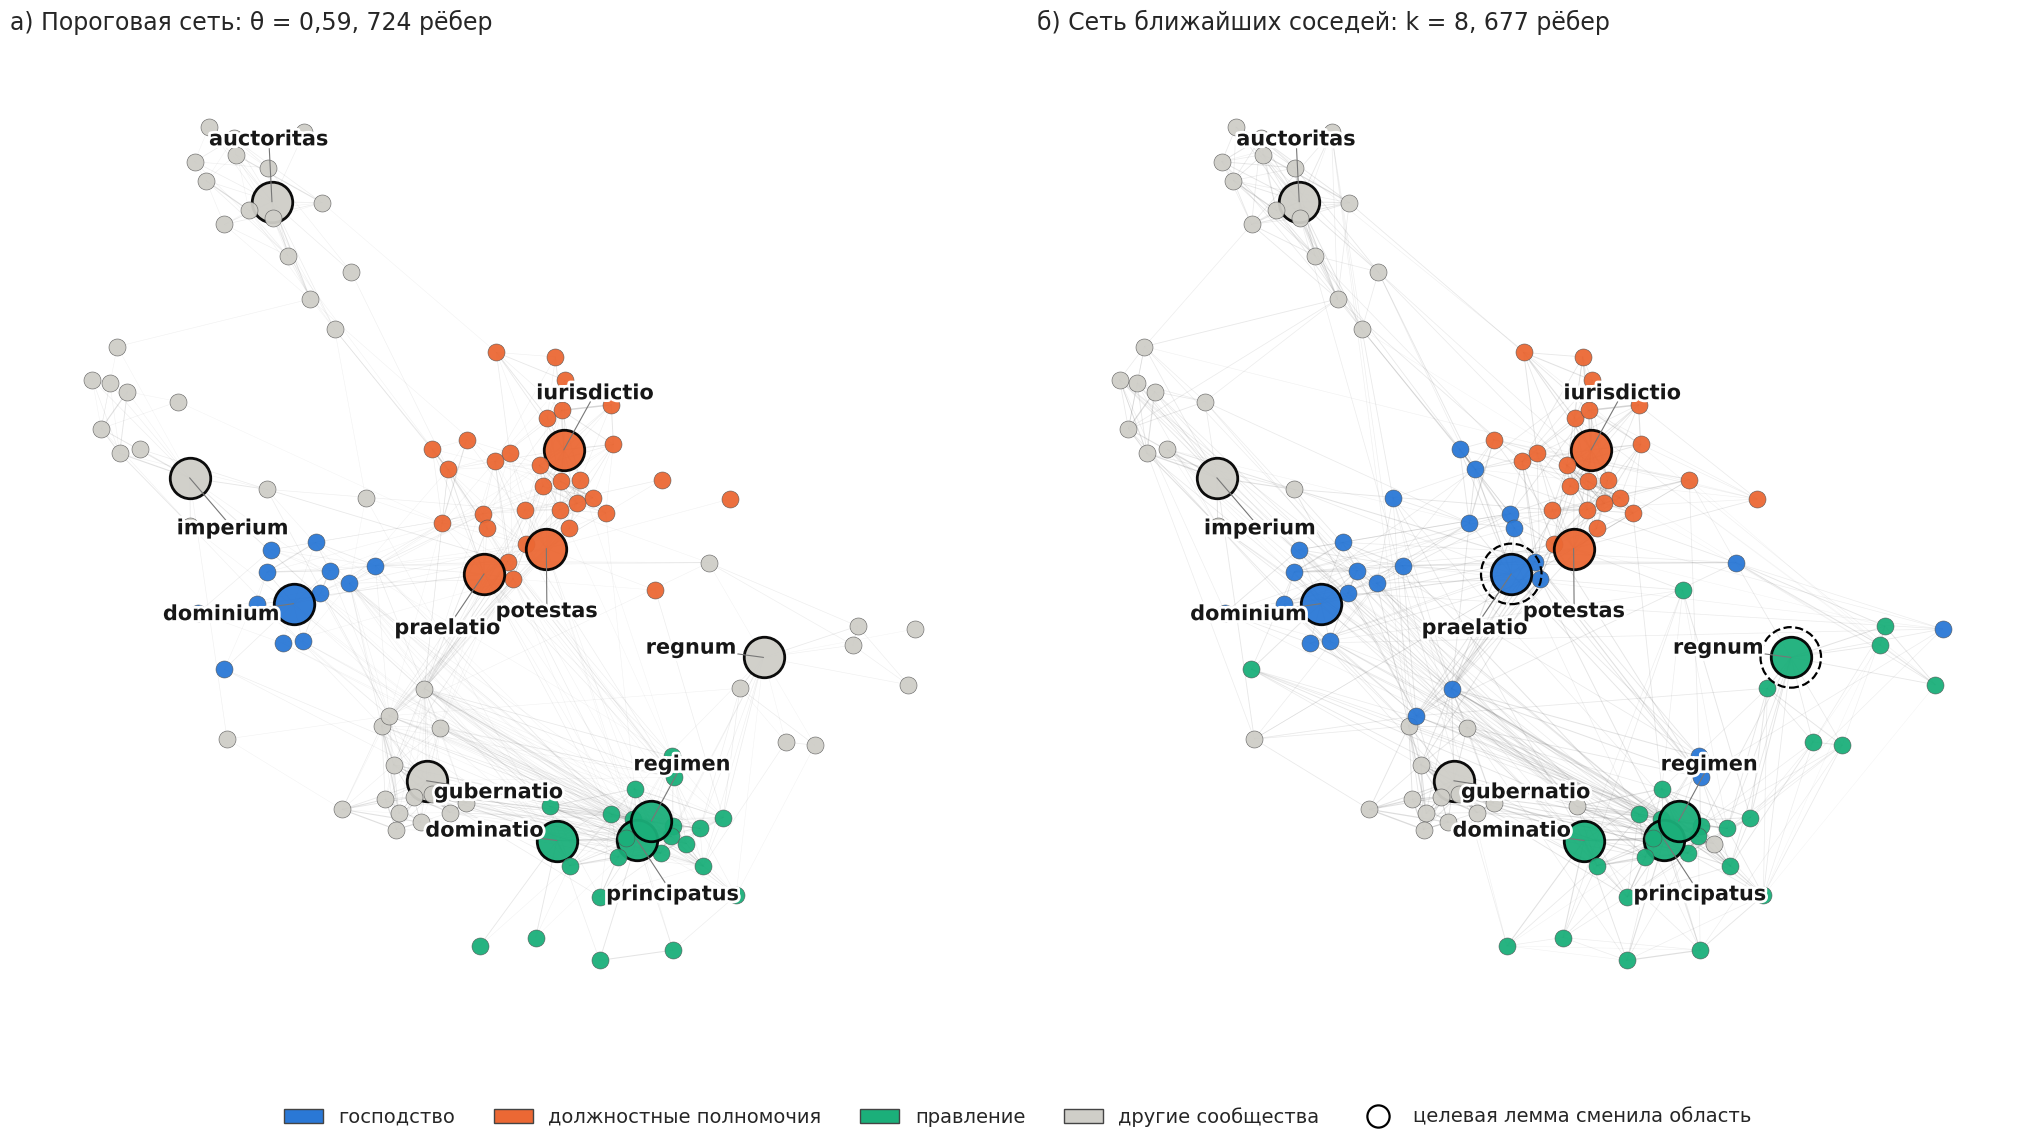

In [10]:
def draw_network_pair(graphs, memberships, panel_titles):
    pos = separate_communities(layout(graphs[0], TARGET_TERMS[0], k=1.5), memberships[0])
    xs = np.array([p[0] for p in pos.values()])
    ys = np.array([p[1] for p in pos.values()])
    span = max(xs.max() - xs.min(), ys.max() - ys.min())
    centre_all = np.array([xs.mean(), ys.mean()])
    base_area = {t: area_colors(memberships[0])[memberships[0][t]] for t in TARGET_TERMS}
    fig, axes = plt.subplots(1, 2, figsize=(26, 12.5))
    fig.subplots_adjust(wspace=0.04, bottom=0.08)
    for ax, graph, memb, title in zip(axes, graphs, memberships, panel_titles):
        colors = area_colors(memb)
        draw_edges(ax, graph, pos, width=(0.35, 0.9), alpha=(0.07, 0.22), top=1.0)
        for node in graph.nodes:
            target = node in TARGET_TERMS
            ax.scatter(*pos[node], s=850 if target else 150, c=[colors[memb[node]]], alpha=0.95,
                       zorder=3, edgecolors="black" if target else EDGE_COLOR,
                       linewidths=2.0 if target else 0.4)
        moved = [t for t in TARGET_TERMS if colors[memb[t]] != base_area[t]]
        if moved:
            ax.scatter([pos[t][0] for t in moved], [pos[t][1] for t in moved], s=1900,
                       facecolors="none", edgecolors="black", linewidths=1.6,
                       linestyles="dashed", zorder=4)
        # Подпись целевой леммы выносится наружу от центра её сообщества (в пороговой сети)
        # и соединяется с узлом выноской: близкие леммы ядра не перекрывают друг друга.
        for t in TARGET_TERMS:
            group = [n for n in graph if memberships[0][n] == memberships[0][t]]
            d = np.array(pos[t]) - np.mean([pos[n] for n in group], axis=0)
            if np.linalg.norm(d) < 0.02 * span:
                d = np.array(pos[t]) - centre_all
            xy = np.array(pos[t]) + d / (np.linalg.norm(d) or 1.0) * 0.075 * span
            ax.plot([pos[t][0], xy[0]], [pos[t][1], xy[1]], color="#777777", lw=0.8, zorder=5)
            draw_label(ax, xy, t, 15, True, 4.0)
        ax.set_title(title, loc="left", fontsize=17, pad=10)
        ax.margins(x=0.10, y=0.10)
        ax.axis("off")
    handles = area_legend() + [Line2D([0], [0], marker="o", color="w", markerfacecolor="none",
                                      markeredgecolor="black", markeredgewidth=1.6, markersize=16,
                                      linestyle="none", label="целевая лемма сменила область")]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=14, frameon=False)
    return fig


save(draw_network_pair(
    (G, G_knn), (membership, knn["membership"]),
    (f"а) Пороговая сеть: θ = {ru(THRESHOLD)}, {G.number_of_edges()} рёбер",
     f"б) Сеть ближайших соседей: k = {KNN_K}, {G_knn.number_of_edges()} рёбер")),
    "fig1_networks")

## 7. Рисунок 2. Матрица косинусного сходства

Квадратная симметричная матрица. Одноцветная шкала начинается от среднего сходства по модели; на ней отмечены 99-й перцентиль и порог сети. Значения не ниже порога набраны полужирным. Диагональ оставлена пустой, чтобы единичные значения не забирали шкалу. Линии разделяют сообщества медоидного разбиения.

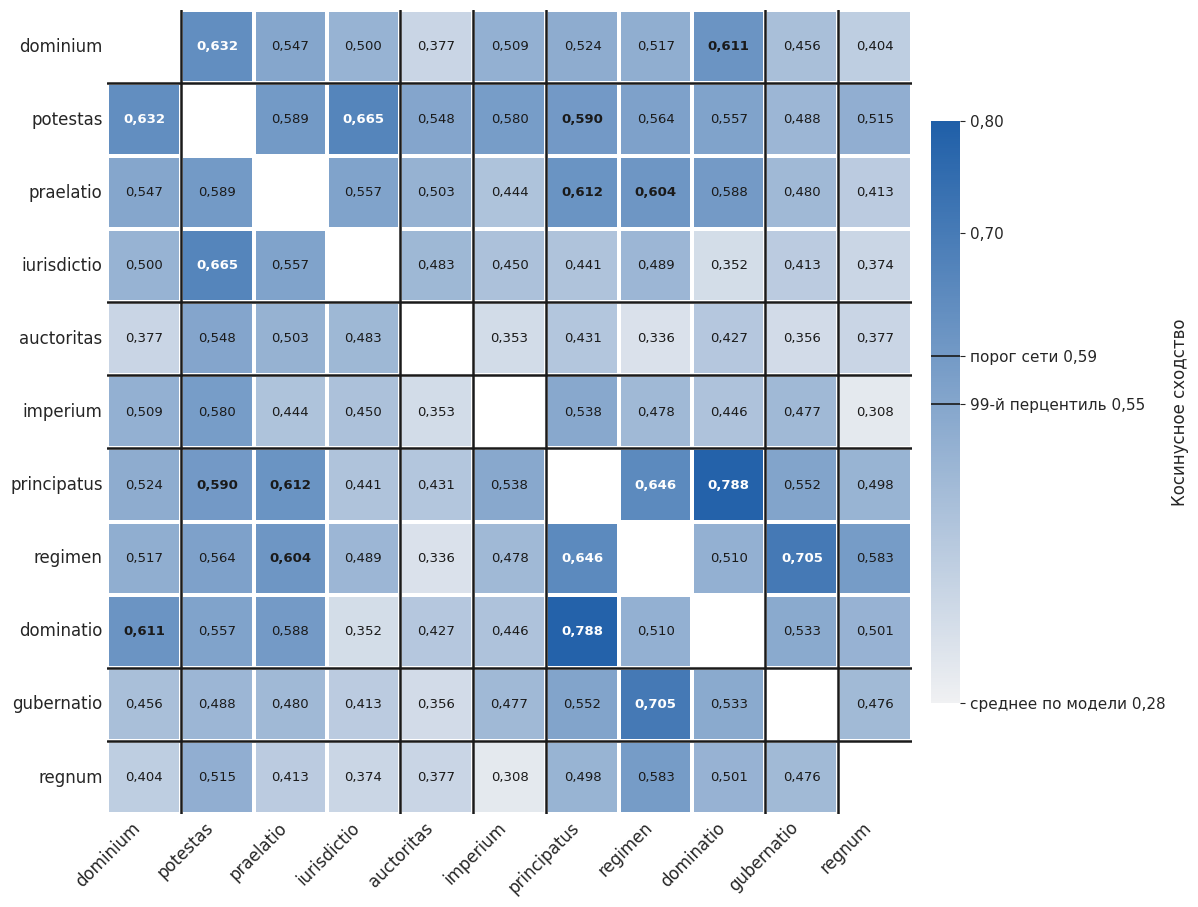

In [11]:
def draw_similarity_square(matrix, memb, mean_sim, p99, threshold, vmax=0.80):
    order = list(matrix.index)
    n = len(order)
    values = matrix.values
    cmap = sns.light_palette(MATRIX_COLOR, as_cmap=True)
    fig, ax = plt.subplots(figsize=(12.5, 10.5))
    sns.heatmap(matrix, mask=np.eye(n, dtype=bool), cmap=cmap, vmin=mean_sim, vmax=vmax,
                square=True, linewidths=1.5, linecolor="white", annot=False,
                cbar_kws={"shrink": 0.72, "pad": 0.02}, ax=ax)
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            v = values[i, j]
            ax.text(j + 0.5, i + 0.5, ru(v, 3), ha="center", va="center", fontsize=9.5,
                    fontweight="bold" if v >= threshold else "normal",
                    color="white" if v >= 0.62 else "#1a1a1a")
    for b in [i for i in range(1, n) if memb[order[i]] != memb[order[i - 1]]]:
        ax.axhline(b, color="#1a1a1a", linewidth=1.8)
        ax.axvline(b, color="#1a1a1a", linewidth=1.8)
    ax.set_xticklabels(order, rotation=45, ha="right", fontsize=12)
    ax.set_yticklabels(order, rotation=0, fontsize=12)
    ax.tick_params(length=0)
    cbar = ax.collections[0].colorbar
    marks = [(mean_sim, f"среднее по модели {ru(mean_sim)}"),
             (p99, f"99-й перцентиль {ru(p99)}"), (threshold, f"порог сети {ru(threshold)}")]
    cbar.set_ticks([m for m, _ in marks] + [0.7, 0.8])
    cbar.set_ticklabels([t for _, t in marks] + ["0,70", "0,80"])
    for m, _ in marks[1:]:
        cbar.ax.axhline(m, color="#1a1a1a", linewidth=1.2)
    cbar.ax.tick_params(labelsize=11)
    cbar.set_label("Косинусное сходство", fontsize=12)
    return fig


order = sorted(TARGET_TERMS, key=lambda t: (membership[t], TARGET_TERMS.index(t)))
idx = [lemmas.index(t) for t in order]
matrix = pd.DataFrame(similarity[np.ix_(idx, idx)], index=order, columns=order)
save(draw_similarity_square(matrix, membership, mean_sim, p99, THRESHOLD), "fig2_similarity_matrix")

## 8. Локальные сети (рисунки 3, 4, 6 и Приложение)

Цвет узла – сообщество основной сети; белые узлы – леммы вне её словаря. Толщина ребра – косинусное сходство, рёбра первого уровня немного толще.

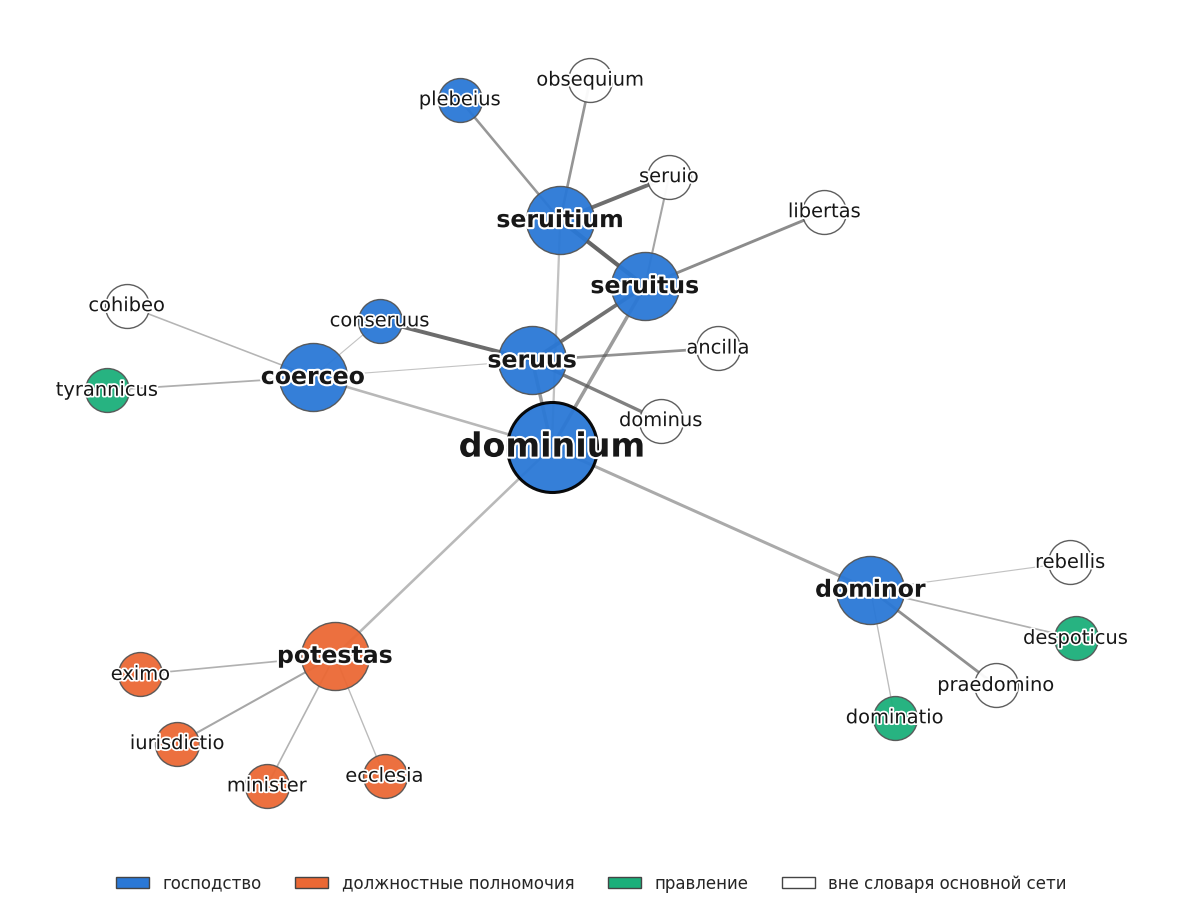

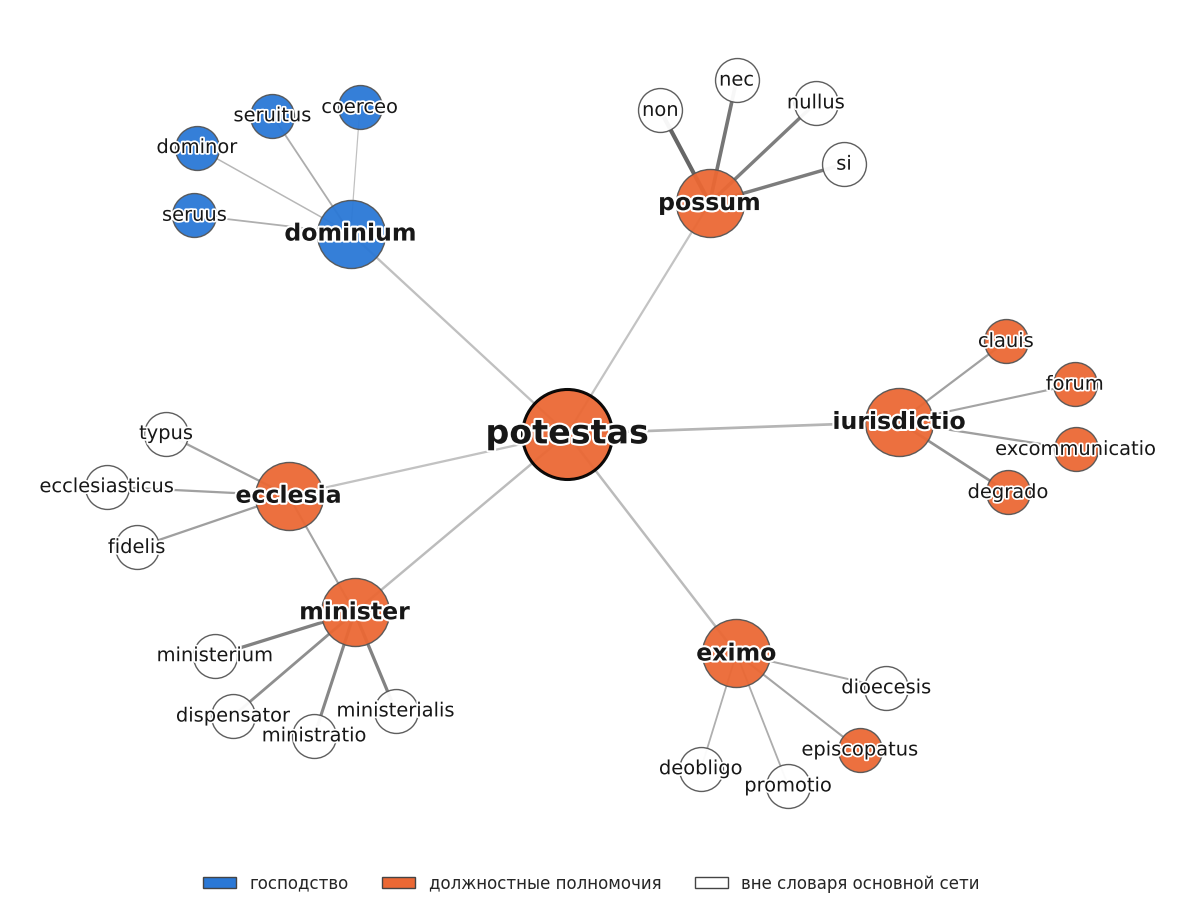

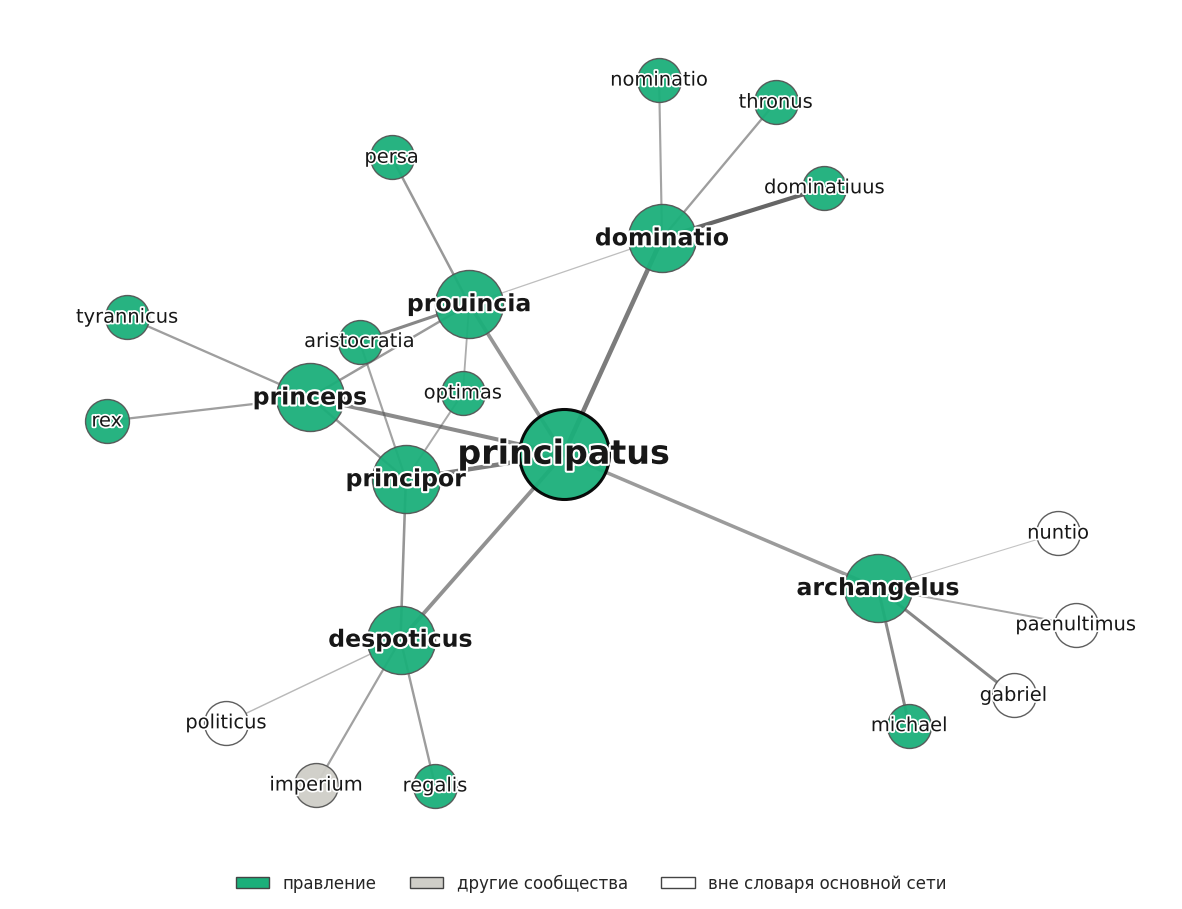

In [12]:
def draw_local(seed_lemma, graph, memb):
    colors = area_colors(memb)
    pos = layout(graph, seed_lemma, k=1.35, iterations=600)
    fig, ax = plt.subplots(figsize=(15, 11))
    draw_edges(ax, graph, pos, width=(0.8, 2.2), alpha=(0.35, 0.55),
               extra=lambda d: 0.8 if d["relation"] == "first" else 0.0)
    present = set()
    for node in graph.nodes:
        level = graph.nodes[node]["level"]
        fill = colors[memb[node]] if node in memb else OUTSIDE_COLOR
        present.add(fill)
        ax.scatter(*pos[node], s={0: 4200, 1: 2400, 2: 1000}[level],
                   c=[fill], alpha=0.95, zorder=3,
                   edgecolors="black" if level == 0 else EDGE_COLOR,
                   linewidths=2.2 if level == 0 else 1.0)
        draw_label(ax, pos[node], node, LOCAL_FONT[level], level <= 1, 3 if level <= 1 else 2.5)
    ax.legend(handles=area_legend(present), loc="lower center", bbox_to_anchor=(0.5, -0.06),
              ncol=5, fontsize=12, frameon=False)
    ax.margins(0.10)
    ax.axis("off")
    return fig


ARTICLE_LOCAL = {"dominium": "fig3_local_dominium", "potestas": "fig4_local_potestas",
                 "principatus": "fig6_local_principatus"}
for term, name in ARTICLE_LOCAL.items():
    save(draw_local(term, local_networks[term], membership), name)

for term in TARGET_TERMS:
    fig = draw_local(term, local_networks[term], membership)
    for fmt in FORMATS:
        fig.savefig(os.path.join(OUT_DIR, "appendix", "local_networks", f"local_{term}.{fmt}"),
                    dpi=FIG_DPI, bbox_inches="tight")
    plt.close(fig)

## 9. Сообщества (рисунок 5 и Приложение)

Показаны только связи внутри сообщества; размер узла растёт с числом таких связей. Подписаны все леммы.

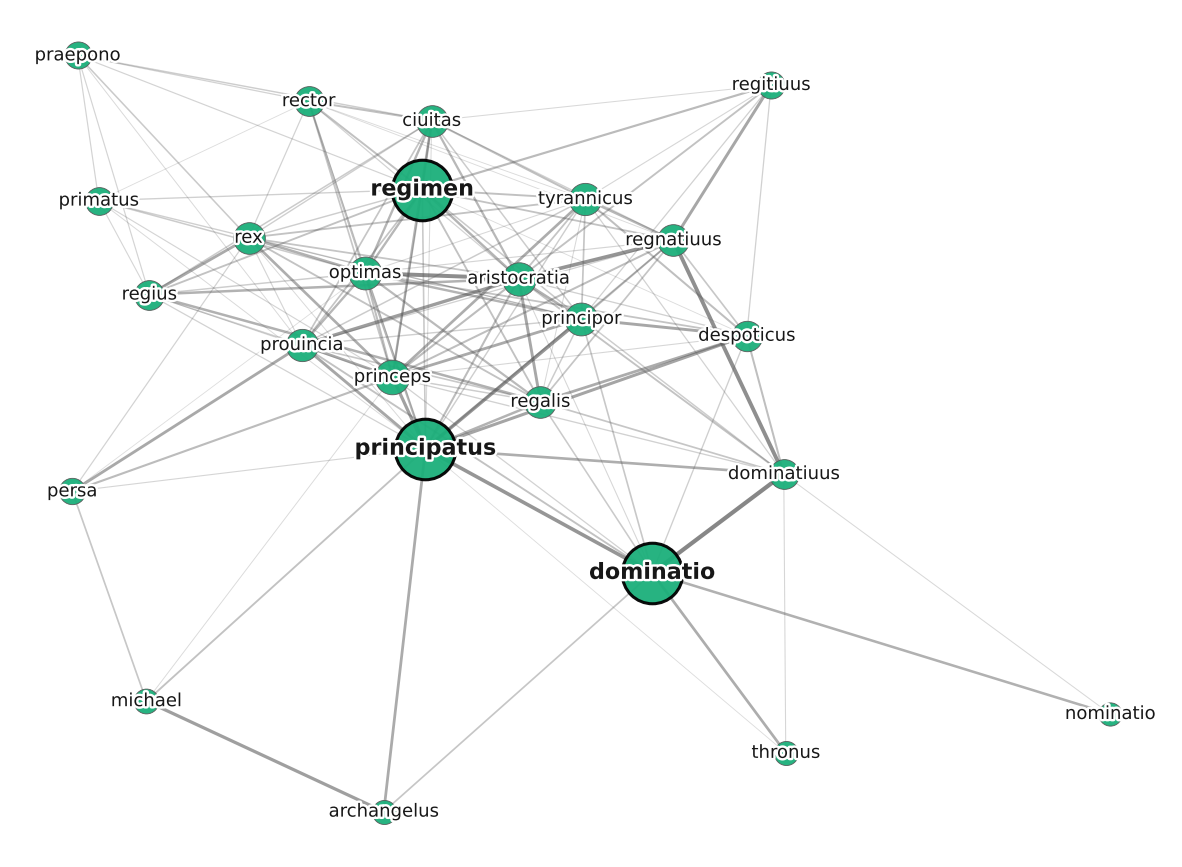

In [13]:
def draw_community(graph, memb, community):
    color = area_colors(memb)[community]
    sub = graph.subgraph([n for n in graph.nodes if memb[n] == community]).copy()
    targets = [t for t in TARGET_TERMS if t in sub]
    anchor = targets[0] if targets else max(sub.degree, key=lambda item: item[1])[0]
    pos = layout(sub, anchor, k=1.6 if sub.number_of_nodes() <= 25 else 1.2)
    fig, ax = plt.subplots(figsize=(15, 11))
    draw_edges(ax, sub, pos, width=(0.6, 2.4), alpha=(0.20, 0.50))
    degree = dict(sub.degree)
    for node in sub.nodes:
        target = node in TARGET_TERMS
        ax.scatter(*pos[node], s=1900 if target else 240 + 20 * degree[node], c=[color], alpha=0.95,
                   zorder=3, edgecolors="black" if target else EDGE_COLOR,
                   linewidths=2.2 if target else 0.6)
        draw_label(ax, pos[node], node, 16 if target else 13, target, 3.5)
    ax.margins(0.06)
    ax.axis("off")
    return fig, anchor


fig, _ = draw_community(G, membership, membership["regimen"])
save(fig, "fig5_community_regimen")

for c in sorted(set(membership.values())):
    fig, anchor = draw_community(G, membership, c)
    for fmt in FORMATS:
        fig.savefig(os.path.join(OUT_DIR, "appendix", "communities", f"community_{c}_{anchor}.{fmt}"),
                    dpi=FIG_DPI, bbox_inches="tight")
    plt.close(fig)

## 10. Список файлов

In [14]:
files = sorted(os.path.relpath(os.path.join(root, f), OUT_DIR)
               for root, _, names in os.walk(OUT_DIR) for f in names if f.endswith(".png"))
print(f"Сохранено в {OUT_DIR}/:")
print("\n".join("  " + f for f in files))

Сохранено в ..\figures\article/:
  appendix\communities\community_1_dominium.png
  appendix\communities\community_2_potestas.png
  appendix\communities\community_3_auctoritas.png
  appendix\communities\community_4_imperium.png
  appendix\communities\community_5_principatus.png
  appendix\communities\community_6_gubernatio.png
  appendix\communities\community_7_regnum.png
  appendix\local_networks\local_auctoritas.png
  appendix\local_networks\local_dominatio.png
  appendix\local_networks\local_dominium.png
  appendix\local_networks\local_gubernatio.png
  appendix\local_networks\local_imperium.png
  appendix\local_networks\local_iurisdictio.png
  appendix\local_networks\local_potestas.png
  appendix\local_networks\local_praelatio.png
  appendix\local_networks\local_principatus.png
  appendix\local_networks\local_regimen.png
  appendix\local_networks\local_regnum.png
  fig1_networks.png
  fig2_similarity_matrix.png
  fig3_local_dominium.png
  fig4_local_potestas.png
  fig5_community_regi

## Подписи к рисункам

**Рисунок 1.** Сеть косинусного сходства одиннадцати обозначений власти и их пятнадцати ближайших соседей (125 лемм): а) пороговая сеть (θ = 0,59, 724 ребра); б) сеть восьми ближайших соседей (677 рёбер). Положение узлов на обеих панелях одинаково. Цветом выделены сообщества трёх контекстных областей в медоидном разбиении каждой сети, серым – остальные сообщества. Пунктирное кольцо отмечает целевые леммы, которые в сети ближайших соседей переходят в другую область.

**Рисунок 2.** Косинусное сходство одиннадцати целевых лемм. Порядок слов и линии соответствуют сообществам медоидного разбиения основной сети. Полужирным выделены значения не ниже порога сети (0,59).

**Рисунок 3.** Локальная сеть *dominium*. Крупным узлом показана целевая лемма, средними – шесть её ближайших соседей, малыми – по четыре ближайших соседа каждого из них. Цвет узла обозначает сообщество основной сети (см. Рисунок 1а); белые узлы – леммы, не вошедшие в её словарь. Толщина ребра соответствует косинусному сходству.

**Рисунок 4.** Локальная сеть *potestas*. Обозначения те же, что на Рисунке 3.

**Рисунок 5.** Сообщество области правления в основной сети (25 лемм). Показаны только связи внутри сообщества; размер узла растёт с числом связей.

**Рисунок 6.** Локальная сеть *principatus*. Обозначения те же, что на Рисунке 3.